<a href="https://colab.research.google.com/github/TianaT6/MSSP607/blob/main/Assignments/Assignment02/MSSP6070_Assignment2_TT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


**Tianyi Tan | MSSP 6070 | Case Study Assignment 2**



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.max_columns', 12)
results = Path('analysis_results')
results.mkdir(exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12})

## 1. Load the data
Each row is a sales order line. Orders can have several lines, and customers can place several orders. Use the original course CSV with Latin-1 encoding.

In [ ]:
data_file = Path('InternetSales.csv')
if not data_file.exists():
    from google.colab import files
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.lower().endswith('.csv')]
    if not csv_files:
        raise ValueError('Please upload the supplied InternetSales.csv file.')
    data_file = Path(csv_files[0])

sales = pd.read_csv(data_file, encoding='latin1', low_memory=False)
print(f'Original data: {len(sales):,} order lines and {sales.shape[1]} columns')

Saving InternetSales.csv to InternetSales.csv
Original data: 60,398 order lines and 60 columns


## 2. Exploratory data analysis
Preview the analysis fields, inspect column types, and check missing values before calculating sales. The original file has 60 columns; the Example displays 59 because its first column is used as the index.

In [ ]:
# Preview the fields used in the analysis.
preview_fields = ['CustomerKey', 'SalesOrderNumber', 'OrderDate',
                  'EnglishCountryRegionName', 'EnglishProductName',
                  'SalesAmount', 'YearlyIncome', 'Gender', 'HouseOwnerFlag']
display(sales[preview_fields].head())
print('Shape:', sales.shape)
print('Columns:', sales.columns.tolist())

,CustomerKey,SalesOrderNumber,OrderDate,EnglishCountryRegionName,EnglishProductName,SalesAmount,YearlyIncome,Gender,HouseOwnerFlag
0,11000,SO43793,1/19/2011,Australia,"Mountain-100 Silver, 38","3,399.99",90000,M,1
1,11000,SO51522,1/18/2013,Australia,"Mountain-200 Silver, 38","2,319.99",90000,M,1
2,11000,SO51522,1/18/2013,Australia,Fender Set - Mountain,21.98,90000,M,1
3,11000,SO57418,5/3/2013,Australia,"Touring-1000 Blue, 46","2,384.07",90000,M,1
4,11000,SO57418,5/3/2013,Australia,Touring Tire,28.99,90000,M,1


Shape: (60398, 60)
Columns: ['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode', 'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title', 'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate', 'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome', 'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation', 'SpanishEducation', 'FrenchEducation', 'EnglishOccupation', 'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag', 'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone', 'DateFirstPurchase', 'CommuteDistance', 'ProductKey', 'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey', 'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey', 'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber', 'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct', 'DiscountAmount', 'ProductStandardCost', 'TotalProductCost', 'SalesAmount', 'TaxAmt', 'Freight', 'CarrierTrackingNumber', 'CustomerPONumber', 'Ord

In [ ]:
# Inspect all original columns and their data types.
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60398 entries, 0 to 60397
Data columns (total 60 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        60398 non-null  int64  
 1   CustomerKey               60398 non-null  int64  
 2   GeographyKey              60398 non-null  int64  
 3   City                      60398 non-null  object 
 4   CountryRegionCode         60398 non-null  object 
 5   EnglishCountryRegionName  60398 non-null  object 
 6   CustomerAlternateKey      60398 non-null  object 
 7   Title                     307 non-null    object 
 8   FirstName                 60398 non-null  object 
 9   MiddleName                34903 non-null  object 
 10  LastName                  60398 non-null  object 
 11  NameStyle                 60398 non-null  bool   
 12  BirthDate                 60398 non-null  object 
 13  MaritalStatus             60398 non-null  object 
 14  Suffix

In [ ]:
sales['OrderDate'] = pd.to_datetime(sales['OrderDate'], format='%m/%d/%Y')
sales['Year'] = sales['OrderDate'].dt.year
print('Dates:', sales['OrderDate'].min().date(), 'to', sales['OrderDate'].max().date())
print(f'Unique orders: {sales["SalesOrderNumber"].nunique():,}')
print(f'Unique customers: {sales["CustomerKey"].nunique():,}')

Dates: 2010-12-29 to 2014-01-28
Unique orders: 27,659
Unique customers: 18,484


In [ ]:
# Summary statistics for the main numerical fields.
display(sales[['OrderQuantity', 'UnitPrice', 'SalesAmount',
               'TotalProductCost', 'YearlyIncome']].describe().round(2))
# Income here is repeated across order lines; Q2 uses unique customers.

,OrderQuantity,UnitPrice,SalesAmount,TotalProductCost,YearlyIncome
count,"60,398.00","60,398.00","60,398.00","60,398.00","60,398.00"
mean,1.00,486.09,486.09,286.07,"59,715.06"
std,0.00,928.49,928.49,552.46,"33,065.43"
min,1.00,2.29,2.29,0.86,"10,000.00"
25%,1.00,7.95,7.95,2.97,"30,000.00"
50%,1.00,29.99,29.99,11.22,"60,000.00"
75%,1.00,539.99,539.99,294.58,"80,000.00"
max,1.00,"3,578.27","3,578.27","2,171.29","170,000.00"


In [ ]:
# Missing values across the original columns.
missing_all = sales.drop(columns='Year').isna().sum().rename('Missing_values')
display(missing_all.to_frame())

,Missing_values
ID,0
CustomerKey,0
GeographyKey,0
City,0
CountryRegionCode,0
EnglishCountryRegionName,0
CustomerAlternateKey,0
Title,60091
FirstName,0
MiddleName,25495


In [ ]:
fields = ['CustomerKey', 'SalesOrderNumber', 'SalesOrderLineNumber', 'OrderDate',
          'EnglishCountryRegionName', 'Gender', 'YearlyIncome', 'HouseOwnerFlag',
          'ProductKey', 'EnglishProductName', 'SalesAmount', 'UnitPrice',
          'OrderQuantity', 'TotalProductCost']
quality = sales[fields].isna().sum().rename('Missing values').to_frame()
display(quality)

,Missing values
CustomerKey,0
SalesOrderNumber,0
SalesOrderLineNumber,0
OrderDate,0
EnglishCountryRegionName,0
Gender,0
YearlyIncome,0
HouseOwnerFlag,0
ProductKey,0
EnglishProductName,0


In [ ]:
print('Duplicate order lines:', sales.duplicated(['SalesOrderNumber', 'SalesOrderLineNumber']).sum())
profiles = ['EnglishCountryRegionName', 'Gender', 'YearlyIncome', 'HouseOwnerFlag']
profile_conflicts = sales.groupby('CustomerKey')[profiles].nunique().gt(1).sum()
display(profile_conflicts.rename('Conflicting customer profiles').to_frame())

Duplicate order lines: 0


,Conflicting customer profiles
EnglishCountryRegionName,0
Gender,0
YearlyIncome,0
HouseOwnerFlag,0


In [ ]:
print('Quantities:', sorted(sales['OrderQuantity'].unique()))
print('Discount amounts:', sorted(sales['DiscountAmount'].unique()))
print('Different product names:', sales['EnglishProductName'].nunique())
print('Different product keys:', sales['ProductKey'].nunique())
customers = sales.drop_duplicates('CustomerKey').copy()

Quantities: [np.int64(1)]
Discount amounts: [np.int64(0)]
Different product names: 130
Different product keys: 158


The fields needed for this analysis have no missing values. Some unused fields, such as titles and tracking numbers, are incomplete. Keep all order lines and leave unused columns unchanged. No duplicate order lines or conflicting customer profiles were found.

## 3. Measurement assumptions and product categories
Sales are `SalesAmount`, excluding separately recorded tax and freight. The file has multiple `CurrencyKey` values but no currency lookup or exchange-rate table. Identical recorded prices for a product across countries support using a common reporting basis, but do not independently verify a USD conversion. Sales, income, and costs are treated as comparable recorded dollar amounts for this assignment.

There is no category column. Bike names start with Mountain-, Road-, or Touring-. Clothing names contain Cap, Vest, Gloves, Jersey, Socks, or Shorts. The listed remaining items are Accessories. These are derived analytical categories. There are **130 different product names and 158 different product keys**; neither count is the number of units sold.

In [ ]:
def product_category(name):
    if name.startswith(('Mountain-', 'Road-', 'Touring-')):
        return 'Bikes'
    if any(word in name for word in ['Cap', 'Vest', 'Gloves', 'Jersey', 'Socks', 'Shorts']):
        return 'Clothing'
    if any(word in name for word in ['Bike Stand', 'Bike Wash', 'Fender', 'Tire', 'Tube',
                                     'Hitch Rack', 'Hydration Pack', 'Bottle', 'Patch Kit', 'Helmet']):
        return 'Accessories'
    raise ValueError('Check product category: ' + name)

sales['Category'] = sales['EnglishProductName'].apply(product_category)
sales['IsBike'] = sales['Category'].eq('Bikes')
mapping = sales[['ProductKey', 'EnglishProductName', 'Category']].drop_duplicates()
display(mapping.groupby('Category').agg(Product_keys=('ProductKey', 'nunique'),
                                       Product_names=('EnglishProductName', 'nunique')))

,Product_keys,Product_names
Category,,
Accessories,22,22
Bikes,116,88
Clothing,20,20


In [ ]:
price_example = sales[sales['EnglishProductName'].eq('Road-150 Red, 48')]
display(price_example.groupby('EnglishCountryRegionName')['UnitPrice'].agg(['min', 'max']))
display(sales.groupby('EnglishCountryRegionName')['CurrencyKey'].unique().to_frame())

,min,max
EnglishCountryRegionName,,
Australia,"3,578.27","3,578.27"
Canada,"3,578.27","3,578.27"
France,"3,578.27","3,578.27"
Germany,"3,578.27","3,578.27"
United Kingdom,"3,578.27","3,578.27"
United States,"3,578.27","3,578.27"


,CurrencyKey
EnglishCountryRegionName,
Australia,"[6, 100]"
Canada,"[19, 100]"
France,"[100, 39, 98]"
Germany,"[100, 29]"
United Kingdom,"[98, 100]"
United States,"[100, 19]"


## 4. Question 1: Sales by year and country region
Years use `OrderDate`. **2010 covers December 29–31 and 2014 covers January 1–28.** Keep these partial periods in the tables, but compare annual growth only for 2011–2013.

In [ ]:
country_year = sales.pivot_table(index='EnglishCountryRegionName', columns='Year',
                                 values='SalesAmount', aggfunc='sum', fill_value=0)
country_year['Total'] = country_year.sum(axis=1)
country_year.loc['Total'] = country_year.sum()
display(country_year.round(2))

Year,2010,2011,2012,2013,2014,Total
EnglishCountryRegionName,,,,,,
Australia,"20,909.78","2,563,732.25","2,128,407.46","4,339,443.38","8,507.72","9,061,000.58"
Canada,"3,578.27","571,571.80","307,604.52","1,085,632.65","9,457.62","1,977,844.86"
France,"3,399.99","410,845.33","648,065.54","1,578,511.80","3,195.06","2,644,017.71"
Germany,0.00,"520,500.16","608,657.98","1,761,876.36","3,277.83","2,894,312.34"
United Kingdom,699.10,"550,591.22","712,700.96","2,124,007.29","3,713.64","3,391,712.21"
United States,"14,833.90","2,458,285.17","1,437,048.73","5,462,078.86","17,542.85","9,389,789.51"
Total,"43,421.04","7,075,525.93","5,842,485.20","16,351,550.34","45,694.72","29,358,677.22"


In [ ]:
annual = sales.groupby('Year')['SalesAmount'].sum().rename('Sales').to_frame()
annual['Period'] = ['Partial', 'Full year', 'Full year', 'Full year', 'Partial']
display(annual)

,Sales,Period
Year,,
2010,"43,421.04",Partial
2011,"7,075,525.93",Full year
2012,"5,842,485.20",Full year
2013,"16,351,550.34",Full year
2014,"45,694.72",Partial


In [ ]:
country_growth = country_year.loc[country_year.index != 'Total', [2011, 2012, 2013]]
country_growth = country_growth.pct_change(axis=1).iloc[:, 1:] * 100
country_growth.columns = ['2011 to 2012 (%)', '2012 to 2013 (%)']
display(country_growth.round(1))

,2011 to 2012 (%),2012 to 2013 (%)
EnglishCountryRegionName,,
Australia,-17.00,103.90
Canada,-46.20,252.90
France,57.70,143.60
Germany,16.90,189.50
United Kingdom,29.40,198.00
United States,-41.50,280.10


Sales fell 17.4% in 2012 and rose 179.9% in 2013. The 2012 decline occurred in the United States, Canada, and Australia; the three European regions grew. All six regions grew in 2013. The United States and Australia contribute 62.8% of total sales. Partial 2014 sales cannot establish a full-year decline.

### Sales by year and product category
The table includes all recorded periods. Figure 1 compares only complete calendar years, 2011–2013.

In [ ]:
category_year = sales.pivot_table(index='Year', columns='Category', values='SalesAmount',
                                  aggfunc='sum', fill_value=0)
category_year = category_year[['Bikes', 'Accessories', 'Clothing']]
category_year['Total'] = category_year.sum(axis=1)
display(category_year.round(2))

Category,Bikes,Accessories,Clothing,Total
Year,,,,
2010,"43,421.04",0.00,0.00,"43,421.04"
2011,"7,075,525.93",0.00,0.00,"7,075,525.93"
2012,"5,839,695.33","2,147.08",642.79,"5,842,485.20"
2013,"15,359,502.36","668,241.53","323,806.45","16,351,550.34"
2014,0.00,"30,371.35","15,323.37","45,694.72"


**Figure 1. Internet sales by year and product category.** Amounts use the common reporting basis described above. Source: course-provided InternetSales.csv; author's calculations.

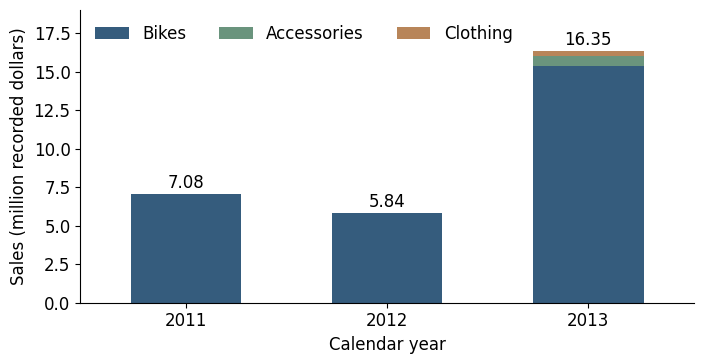

In [ ]:
colors = ['#355C7D', '#6A947D', '#B88559']
fig, ax = plt.subplots(figsize=(7.2, 3.8))
plot_data = category_year.loc[2011:2013, ['Bikes', 'Accessories', 'Clothing']] / 1_000_000
plot_data.plot.bar(stacked=True, ax=ax, color=colors, width=0.55, rot=0)
ax.set(xlabel='Calendar year', ylabel='Sales (million recorded dollars)', ylim=(0, 19))
ax.legend(title=None, frameon=False, ncol=3, loc='upper left')
for i, value in enumerate(plot_data.sum(axis=1)):
    ax.text(i, value + 0.4, f'{value:.2f}', ha='center')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(results / 'figure1_annual_category_sales.png', dpi=220)
plt.show()

## 5. Question 2: Yearly income and gender by country region
Count each customer once. Income is numerical, so report count, mean, min, max, and sample standard deviation (`ddof=1`, the pandas default). Gender is categorical, so report counts and percentages, not min, max, or standard deviation of arbitrary gender codes.

In [ ]:
income_region = customers.groupby('EnglishCountryRegionName')['YearlyIncome'].agg(
    Customers='count', Mean='mean', Min='min', Max='max', SD='std')

display(income_region.round(2))

,Customers,Mean,Min,Max,SD
EnglishCountryRegionName,,,,,
Australia,3591,"64,338.62",10000,170000,"31,830.00"
Canada,1571,"57,167.41",10000,170000,"20,251.52"
France,1810,"35,762.43",10000,110000,"27,277.40"
Germany,1780,"42,943.82",10000,130000,"35,493.58"
United Kingdom,1913,"52,169.37",10000,170000,"48,431.99"
United States,7819,"63,616.83",10000,170000,"25,706.48"


In [ ]:
income_gender = customers.groupby(['EnglishCountryRegionName', 'Gender'])['YearlyIncome'].agg(
    Customers='count', Mean='mean', Min='min', Max='max', SD='std')

display(income_gender.round(2))

Customers      Mean    Min     Max        SD
EnglishCountryRegionName Gender                                              
Australia                F            1777 65,284.19  10000  160000 31,164.36
                         M            1814 63,412.35  10000  170000 32,450.71
Canada                   F             767 56,505.87  10000  170000 19,181.55
                         M             804 57,798.51  10000  170000 21,214.77
France                   F             893 35,341.55  10000  110000 26,915.85
                         M             917 36,172.30  10000  110000 27,633.45
Germany                  F             874 43,810.07  10000  130000 35,715.76
                         M             906 42,108.17  10000  130000 35,277.49
United Kingdom           F             934 52,184.15  10000  170000 48,288.44
                         M             979 52,155.26  10000  170000 48,593.22
United States            F            3888 63,276.75  10000  170000 25,166.56
                         M            3931 63,953.19  10000  170000 26,228.43

In [ ]:
gender_counts = pd.crosstab(customers['EnglishCountryRegionName'], customers['Gender'])
gender_percentages = gender_counts.div(gender_counts.sum(axis=1), axis=0) * 100
display(gender_counts)
display(gender_percentages.round(1))

Gender,F,M
EnglishCountryRegionName,,
Australia,1777,1814
Canada,767,804
France,893,917
Germany,874,906
United Kingdom,934,979
United States,3888,3931


Gender,F,M
EnglishCountryRegionName,,
Australia,49.50,50.50
Canada,48.80,51.20
France,49.30,50.70
Germany,49.10,50.90
United Kingdom,48.80,51.20
United States,49.70,50.30


Mean yearly income is about 64,000 among Australian customers and 36,000 among French customers. Within each country, mean incomes differ by less than 2,000 between recorded genders, and customer counts are close to balanced. This describes observed customers; it does not measure the wealth of an entire country or prove equal purchasing preferences.

## 6. Question 3: Average price of the leading product category
“Most sales” means the highest total revenue. Average selling price equals sales divided by units sold. Here, every line has quantity one and no discount, so it also equals mean `UnitPrice`. It is a transaction-weighted price, not a catalogue list price.

Product gross margin is `(SalesAmount − TotalProductCost) / SalesAmount`. It excludes delivery, marketing, returns, and other operating costs and is not net profit.

In [ ]:
category_summary = sales.groupby('Category').agg(
    Sales=('SalesAmount', 'sum'), Product_cost=('TotalProductCost', 'sum'),
    Units=('OrderQuantity', 'sum'), Buyers=('CustomerKey', 'nunique'))
category_summary['Sales_share_pct'] = category_summary['Sales'] / sales['SalesAmount'].sum() * 100
category_summary['Average_price'] = category_summary['Sales'] / category_summary['Units']
category_summary['Product_gross_margin_pct'] = (1 - category_summary['Product_cost'] / category_summary['Sales']) * 100
category_summary = category_summary.sort_values('Sales', ascending=False)
display(category_summary.round(2))

,Sales,Product_cost,Units,Buyers,Sales_share_pct,Average_price,Product_gross_margin_pct
Category,,,,,,,
Bikes,"28,318,144.65","16,812,348.15",15205,9132,96.46,"1,862.42",40.63
Accessories,"700,759.96","262,085.39",36092,15114,2.39,19.42,62.60
Clothing,"339,772.61","203,360.03",9101,6852,1.16,37.33,40.15


In [ ]:
print('Top category:', category_summary.index[0])
print(f'Average bike selling price: {category_summary.loc["Bikes", "Average_price"]:,.2f} recorded dollars')
display(sales.groupby('Category')['OrderDate'].min().rename('First observed sale').to_frame())

Top category: Bikes
Average bike selling price: 1,862.42 recorded dollars


,First observed sale
Category,
Accessories,2012-12-28
Bikes,2010-12-29
Clothing,2012-12-28


Bikes generate 96.5% of total revenue, averaging 1,862.42 recorded dollars per unit. Accessories have a higher product margin but account for only 2.4% of revenue. The first observed accessory and clothing records are December 28, 2012; this does not prove the actual launch date of those categories.

### Top ten individual products
This follows the Example's product-level analysis. Rank individual product names by sales revenue, while keeping the category-level answer above separate. Product gross profit is sales minus recorded product cost, before other business expenses.

In [ ]:
product_summary = sales.groupby('EnglishProductName').agg(
    Units=('OrderQuantity', 'sum'), Average_price=('UnitPrice', 'mean'),
    Sales=('SalesAmount', 'sum'), Product_cost=('TotalProductCost', 'sum'))
product_summary['Product_gross_profit'] = product_summary['Sales'] - product_summary['Product_cost']
top_products = product_summary.sort_values('Sales', ascending=False).head(10)
display(top_products.round(2))

,Units,Average_price,Sales,Product_cost,Product_gross_profit
EnglishProductName,,,,,
"Mountain-200 Black, 46",620,"2,215.27","1,373,469.55","746,847.97","626,621.57"
"Mountain-200 Black, 42",614,"2,220.10","1,363,142.09","741,382.49","621,759.61"
"Mountain-200 Silver, 38",596,"2,247.42","1,339,462.79","728,598.36","610,864.43"
"Mountain-200 Silver, 46",580,"2,243.28","1,301,100.10","707,609.63","593,490.47"
"Mountain-200 Black, 38",582,"2,224.86","1,294,866.14","704,388.68","590,477.46"
"Mountain-200 Silver, 42",560,"2,245.42","1,257,434.57","683,922.64","573,511.94"
"Road-150 Red, 48",337,"3,578.27","1,205,876.99","731,726.15","474,150.84"
"Road-150 Red, 62",336,"3,578.27","1,202,298.72","729,554.85","472,743.87"
"Road-150 Red, 52",302,"3,578.27","1,080,637.54","655,730.85","424,906.69"


Mountain-200 Black, 46 leads individual product revenue. Its mean selling price is different from the mean for the whole Bikes category because the category includes many models and sizes.

### Additional product detail
Compare bike types and models to identify which products contribute most to historical revenue.

In [ ]:
bikes = sales[sales['IsBike']].copy()
bikes['Subcategory'] = bikes['EnglishProductName'].str.split('-').str[0]
subcategory = bikes.groupby('Subcategory').agg(Sales=('SalesAmount', 'sum'), Units=('OrderQuantity', 'sum'))
subcategory['Average_price'] = subcategory['Sales'] / subcategory['Units']
subcategory['Share_of_all_sales_pct'] = subcategory['Sales'] / sales['SalesAmount'].sum() * 100
display(subcategory.round(2))

,Sales,Units,Average_price,Share_of_all_sales_pct
Subcategory,,,,
Mountain,"9,952,759.56",4970,"2,002.57",33.90
Road,"14,520,584.04",8068,"1,799.77",49.46
Touring,"3,844,801.05",2167,"1,774.25",13.10


In [ ]:
bikes['Model'] = bikes['EnglishProductName'].str.replace(r',\s*\d+$', '', regex=True)
model_summary = bikes.groupby('Model')['SalesAmount'].sum().sort_values(ascending=False).to_frame('Sales')
model_summary['Share_of_all_sales_pct'] = model_summary['Sales'] / sales['SalesAmount'].sum() * 100
display(model_summary.head(5).round(2))

,Sales,Share_of_all_sales_pct
Model,,
Road-150 Red,"5,549,896.77",18.90
Mountain-200 Black,"4,031,477.78",13.73
Mountain-200 Silver,"3,897,997.46",13.28
Road-250 Black,"2,675,991.82",9.11
Road-250 Red,"1,775,268.30",6.05


## 7. Question 4: Does home ownership make a difference?
Compare total sales and cumulative sales per customer, then check whether the average difference is similar within each country and income band. `HouseOwnerFlag` is 1 for homeowners and 0 for non-homeowners. These are descriptive comparisons among buyers, not causal effects or website conversion rates.

In [ ]:
customer_sales = sales.groupby('CustomerKey').agg(
    Revenue=('SalesAmount', 'sum'), Orders=('SalesOrderNumber', 'nunique'),
    First_order=('OrderDate', 'min'), Bought_bike=('IsBike', 'max'))
customer_sales = customer_sales.join(customers.set_index('CustomerKey')[
    ['EnglishCountryRegionName', 'YearlyIncome', 'Gender', 'HouseOwnerFlag']])

In [ ]:
home_summary = customer_sales.groupby('HouseOwnerFlag').agg(
    Customers=('Revenue', 'size'), Sales=('Revenue', 'sum'),
    Mean_sales=('Revenue', 'mean'), Median_sales=('Revenue', 'median'),
    Orders=('Orders', 'sum'), Bike_buyer_pct=('Bought_bike', 'mean'), Mean_income=('YearlyIncome', 'mean'))
home_summary['Bike_buyer_pct'] *= 100
home_summary['Customer_share_pct'] = home_summary['Customers'] / home_summary['Customers'].sum() * 100
home_summary['Sales_share_pct'] = home_summary['Sales'] / home_summary['Sales'].sum() * 100
home_summary['Orders_per_customer'] = home_summary['Orders'] / home_summary['Customers']
home_summary['Average_order_value'] = home_summary['Sales'] / home_summary['Orders']
display(home_summary.round(2))
home_gap = (home_summary.loc[1, 'Mean_sales'] / home_summary.loc[0, 'Mean_sales'] - 1) * 100
print(f'Overall difference in mean sales per customer: {home_gap:.1f}%')

,Customers,Sales,Mean_sales,Median_sales,Orders,Bike_buyer_pct,Mean_income,Customer_share_pct,Sales_share_pct,Orders_per_customer,Average_order_value
HouseOwnerFlag,,,,,,,,,,,
0,5982,"8,973,327.42","1,500.05",209.96,8601,48.86,"55,172.18",32.36,30.56,1.44,"1,043.29"
1,12502,"20,385,349.80","1,630.57",342.00,19058,49.66,"58,326.67",67.64,69.44,1.52,"1,069.65"


Overall difference in mean sales per customer: 8.7%


In [ ]:
home_country = customer_sales.pivot_table(index='EnglishCountryRegionName', columns='HouseOwnerFlag',
                                          values='Revenue', aggfunc='mean')
home_country.columns = ['Non_homeowner_mean', 'Homeowner_mean']
home_country['Difference_pct'] = (home_country['Homeowner_mean'] / home_country['Non_homeowner_mean'] - 1) * 100
display(home_country.round(2))

,Non_homeowner_mean,Homeowner_mean,Difference_pct
EnglishCountryRegionName,,,
Australia,"2,500.68","2,536.09",1.42
Canada,"1,141.96","1,316.04",15.24
France,"1,018.62","1,699.16",66.81
Germany,"1,272.06","1,806.90",42.05
United Kingdom,"1,466.36","1,928.59",31.52
United States,"1,213.75","1,195.59",-1.50


In [ ]:
customer_sales['Income_band'] = pd.cut(customer_sales['YearlyIncome'],
    bins=[0, 30000, 60000, 90000, float('inf')], labels=['10-30k', '40-60k', '70-90k', '100k+'])
home_income = customer_sales.pivot_table(index='Income_band', columns='HouseOwnerFlag',
    values='Revenue', aggfunc='mean', observed=True)
home_income.columns = ['Non_homeowner_mean', 'Homeowner_mean']
home_income['Difference_pct'] = (home_income['Homeowner_mean'] / home_income['Non_homeowner_mean'] - 1) * 100
display(home_income.round(2))

,Non_homeowner_mean,Homeowner_mean,Difference_pct
Income_band,,,
10-30k,"1,046.67","1,333.33",27.39
40-60k,"1,309.13","1,455.57",11.19
70-90k,"2,253.24","1,855.87",-17.64
100k+,"1,941.85","2,314.36",19.18


In [ ]:
home_mix = pd.crosstab(sales['HouseOwnerFlag'], sales['Category'], values=sales['SalesAmount'], aggfunc='sum')
home_mix = home_mix.div(home_mix.sum(axis=1), axis=0) * 100
display(home_mix.round(3))

Category,Accessories,Bikes,Clothing
HouseOwnerFlag,,,
0,2.39,96.45,1.16
1,2.39,96.46,1.16


Homeowners contribute more total sales because they are a larger observed group and have somewhat higher mean spending. Their cumulative mean spending is 1,630.57 versus 1,500.05 recorded dollars, a gap of 8.7%. The gap is small in the United States (−1.5%) and Australia (+1.4%), but larger in France, Germany, and the United Kingdom. It reverses within the 70–90k income band. Category revenue shares are almost identical for the two groups. These separate checks do not jointly control all customer differences. The data do not establish that owning a home causes more spending.

## 8. Customer patterns relevant to growth
Country comparisons use cumulative spending among observed buyers, not traffic conversion. Customers have different lengths of purchase history. A 2013-only comparison uses one common calendar year as a descriptive sensitivity check.

In [ ]:
country_customers = customer_sales.groupby('EnglishCountryRegionName').agg(
    Customers=('Revenue', 'size'), Sales=('Revenue', 'sum'),
    Sales_per_customer=('Revenue', 'mean'), Orders=('Orders', 'sum'), Bike_buyer_pct=('Bought_bike', 'mean'))
country_customers['Bike_buyer_pct'] *= 100
country_customers['Average_order_value'] = country_customers['Sales'] / country_customers['Orders']
display(country_customers.round(2))

,Customers,Sales,Sales_per_customer,Orders,Bike_buyer_pct,Average_order_value
EnglishCountryRegionName,,,,,,
Australia,3591,"9,061,000.58","2,523.25",6718,60.01,"1,348.76"
Canada,1571,"1,977,844.86","1,258.97",3375,41.76,586.03
France,1810,"2,644,017.71","1,460.78",2484,45.08,"1,064.42"
Germany,1780,"2,894,312.34","1,626.02",2484,50.79,"1,165.18"
United Kingdom,1913,"3,391,712.21","1,772.98",3031,53.95,"1,119.01"
United States,7819,"9,389,789.51","1,200.89",9567,45.65,981.48


In [ ]:
sales_2013 = sales[sales['Year'].eq(2013)]
buyers_2013 = sales_2013.groupby('CustomerKey').agg(
    Revenue=('SalesAmount', 'sum'), Country=('EnglishCountryRegionName', 'first'), Bought_bike=('IsBike', 'max'))
country_2013 = buyers_2013.groupby('Country').agg(
    Active_customers=('Revenue', 'size'), Sales_per_customer=('Revenue', 'mean'), Bike_buyer_pct=('Bought_bike', 'mean'))
country_2013['Bike_buyer_pct'] *= 100
display(country_2013.round(2))
us_customers = customer_sales[customer_sales['EnglishCountryRegionName'].eq('United States')]
print('U.S. observed buyers with no bike purchase:', int((~us_customers['Bought_bike']).sum()))

,Active_customers,Sales_per_customer,Bike_buyer_pct
Country,,,
Australia,3532,"1,228.61",60.70
Canada,1402,774.35,36.59
France,1697,930.18,45.14
Germany,1701,"1,035.79",52.03
United Kingdom,1867,"1,137.66",54.90
United States,7230,755.47,44.95


U.S. observed buyers with no bike purchase: 4250


**Figure 2. Sales per active customer by country, 2013.** Using the same calendar year reduces differences in observation length. This remains a comparison among buyers, not website conversion. Source: course-provided InternetSales.csv; author's calculations.

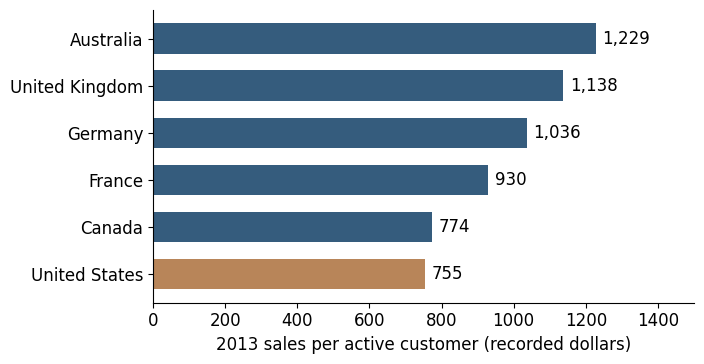

In [ ]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
plot_data = country_2013['Sales_per_customer'].sort_values()
bar_colors = ['#B88559' if x == 'United States' else '#355C7D' for x in plot_data.index]
ax.barh(plot_data.index, plot_data, color=bar_colors, height=0.65)
ax.set(xlabel='2013 sales per active customer (recorded dollars)', ylabel='', xlim=(0, 1500))
for i, value in enumerate(plot_data):
    ax.text(value + 18, i, f'{value:,.0f}', va='center')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(results / 'figure2_country_spending_2013.png', dpi=220)
plt.show()

In [ ]:
bike_counts = bikes.groupby('CustomerKey').size()
non_bike_revenue = sales[~sales['IsBike']].groupby('CustomerKey')['SalesAmount'].sum()
gear_per_bike_buyer = non_bike_revenue.reindex(bike_counts.index, fill_value=0)
purchase_patterns = pd.Series({
    'Bike buyers': len(bike_counts),
    'Customers with one bike purchase': int(bike_counts.eq(1).sum()),
    'Customers with two or more bike purchases': int(bike_counts.ge(2).sum()),
    'Customers with two or more orders (%)': customer_sales['Orders'].ge(2).mean() * 100,
    'Bike buyers who also bought non-bike products (%)': gear_per_bike_buyer.gt(0).mean() * 100,
    'Non-bike revenue per bike buyer': gear_per_bike_buyer.mean()
}, name='Value').to_frame()
display(purchase_patterns.round(2))

,Value
Bike buyers,"9,132.00"
Customers with one bike purchase,"4,128.00"
Customers with two or more bike purchases,"5,004.00"
Customers with two or more orders (%),37.14
Bike buyers who also bought non-bike products (%),84.07
Non-bike revenue per bike buyer,44.68


### Economic illustration
Estimate the revenue and product gross profit associated with 100 genuinely additional bike purchases. This is a scenario, not a sales forecast.

In [ ]:
illustrative_bikes = 100
historical_bike_price = category_summary.loc['Bikes', 'Average_price']
historical_bike_margin = category_summary.loc['Bikes', 'Product_gross_margin_pct'] / 100
illustration = pd.Series({
    'Hypothetical incremental bike purchases': illustrative_bikes,
    'Historical mean selling price': historical_bike_price,
    'Illustrative incremental revenue': illustrative_bikes * historical_bike_price,
    'Historical product gross margin (%)': historical_bike_margin * 100,
    'Illustrative product gross profit before extra costs': illustrative_bikes * historical_bike_price * historical_bike_margin
}, name='Value').to_frame()
display(illustration.round(2))

,Value
Hypothetical incremental bike purchases,100.00
Historical mean selling price,"1,862.42"
Illustrative incremental revenue,"186,242.32"
Historical product gross margin (%),40.63
Illustrative product gross profit before extra costs,"75,671.14"


The United States has the largest customer base and lower spending per customer than Australia. Its bike-buyer share is 45.6%, compared with 60.0% in Australia; it is **not** the lowest, since Canada is 41.8% and France is 45.1%. The U.S.–Australia spending gap also appears in 2013-only data.

Recommend a controlled test of bike offers to U.S. customers with no observed bike purchase, plus a separate test of optional accessory bundles. Compare customer groups assigned at random and measure additional contribution after discounts, delivery, returns, campaign spending, and implementation costs. Cross-buying research supports testing offers based on purchase history (Kumar et al.), but does not supply an effect size for this dataset.

The 100-bike calculation is an arithmetic illustration, **not a forecast, response-rate estimate, or available marketing budget**. It assumes genuinely additional purchases at the historical price and product margin. A second-bike offer would target the 4,128 customers with exactly one observed bike purchase, not all 9,132 bike buyers. No replacement interval is estimated.

## 9. Export results
The exports contain all four required answers, supplementary checks, the product mapping, and the two figures. Percentages in tables are stored in percentage points (for example, 96.46 means 96.46%).

In [ ]:
tables = {
    'sales_by_country_year': country_year,
    'annual_sales': annual,
    'country_sales_growth': country_growth,
    'sales_by_category_year': category_year,
    'category_summary': category_summary,
    'bike_subcategories': subcategory,
    'bike_models': model_summary,
    'top_10_products': top_products,
    'income_by_region': income_region,
    'income_by_region_gender': income_gender,
    'gender_counts': gender_counts,
    'gender_percentages': gender_percentages,
    'home_ownership_summary': home_summary,
    'home_ownership_by_country': home_country,
    'home_ownership_by_income': home_income,
    'home_ownership_category_mix': home_mix,
    'country_customer_summary': country_customers,
    'country_customer_summary_2013': country_2013,
    'purchase_patterns': purchase_patterns,
    'contribution_illustration': illustration
}
for name, table in tables.items():
    table.to_csv(results / f'{name}.csv')
mapping.to_csv(results / 'product_category_mapping.csv', index=False)
quality.to_csv(results / 'missing_value_check.csv')
print(f'Saved {len(tables) + 2} CSV tables and 2 figures in analysis_results.')

Saved 22 CSV tables and 2 figures in analysis_results.


## References
- Kumar, V., Morris George, and Joseph Pancras. “Cross-Buying in Retailing: Drivers and Consequences.” *Journal of Retailing*, vol. 84, no. 1, 2008, pp. 15–27. https://doi.org/10.1016/j.jretai.2008.01.007.
- Microsoft. “AdventureWorks Sample Databases.” *Microsoft Learn*, https://learn.microsoft.com/en-us/sql/samples/adventureworks-install-configure. Accessed 3 Nov. 2026.
- Microsoft Corporation. *InternetSales.csv*. Adventure Works Internet Sales Dataset, MSSP 6070, University of Pennsylvania, course-provided CSV.